In [1]:
from dataloader import load_all_data
import pandas as pd
import numpy as np

import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
plt.rcParams['text.usetex'] = True
plt.rcParams['text.latex.preamble'] = r'''\usepackage{libertine}\usepackage{fontawesome5}\usepackage{xcolor}'''
plt.rcParams['ps.usedistiller'] = 'xpdf'
import seaborn as sns
sns.set_theme(style='ticks')
from statannotations.Annotator import Annotator

In [2]:
colors = ['#c26f6d', '#d9a6a4', '#f2dfdd', '#e4e5eb', '#aab8d0', '#6e90bf']
interfaces = {
    'pointwise':        'UI1',
    'pairwise':         'UI2',
    'listwise-rating':  'UI3',
    'listwise-notie':   'UI4',
    'listwise-cantie':  'UI5',
    'listwise-ranking': 'UI6',
}
pairs = [
    ('pointwise', 'pairwise'),               # H1
    ('pointwise', 'listwise-rating'),        # H2a
    ('pairwise',  'listwise-cantie'),        # H2b
    ('listwise-rating', 'listwise-cantie'),  # H3a
    ('listwise-notie', 'listwise-cantie'),   # H3b
    ('listwise-ranking', 'pairwise'),        # H4a
    ('listwise-ranking', 'listwise-rating'), # H4b
    ('listwise-ranking', 'listwise-notie'),  # H4c
    ('listwise-ranking', 'listwise-cantie'), # H4d
]

df_begins, df_all, df_finishs, df_demographic = load_all_data()

pointwise
pairwise
listwise-rating
listwise-notie
listwise-cantie
listwise-ranking
pointwise
pairwise
listwise-rating
listwise-notie
listwise-cantie
listwise-ranking


In [8]:
df_incomplete = df_all[['userID', 'domain', 'taskID', 'interface', 'skip', 'rating']]
for idx, row in df_incomplete.iterrows():
    if row.interface == 'pointwise':
        df_incomplete.loc[idx, 'skip'] = 1 if row.skip else 0
        continue

    if row.interface == 'pairwise':
        df_incomplete.loc[idx, 'skip'] = 2 if row.skip else 0
        continue

    if row.interface == 'listwise-rating':
        count = 0
        for v in row.skip:
            if v:
                count += 1
        df_incomplete.loc[idx, 'skip'] = count
        continue

    if row.interface == 'listwise-notie' or row.interface == 'listwise-cantie' or row.interface == 'listwise-ranking':
        for hist in row.rating:
            if hist['rating'] == 'I don\'t know':
                df_incomplete.loc[idx, 'skip'] += 1
        continue

    df_incomplete.loc[idx, 'skip'] = 0

df_incomplete = df_incomplete.groupby(['userID', 'domain', 'taskID', 'interface']).sum().reset_index()
df_incomplete = df_incomplete[['userID', 'domain', 'taskID', 'interface', 'skip']]
df_incomplete.rename(columns={'skip': 'incomplete'}, inplace=True)
df_incomplete.to_csv('processed/incomplete.csv', index=False)
df_incomplete

,userID,domain,taskID,interface,incomplete
0,P042,image,1,listwise-rating,0
1,P042,image,2,listwise-rating,0
2,P042,image,3,listwise-rating,0
3,P248,image,1,pairwise,2
4,P248,image,2,pairwise,0
...,...,...,...,...,...
1073,P160,image,2,listwise-notie,0
1074,P160,image,3,listwise-notie,5
1075,P052,image,1,pairwise,4
1076,P052,image,2,pairwise,0


In [9]:
for idx, row in df_incomplete.iterrows():
    if row.interface == 'pointwise' or row.interface == 'listwise-notie':
        df_incomplete.loc[idx, 'ties'] = 0
    if row.interface == 'pairwise':
        df_pairwise = df_all[df_all.interface == 'pairwise'][['userID', 'taskID', 'interface', 'skip', 'rating', 'selection']]
        ties = 0
        for sel in df_pairwise[(df_pairwise.userID == row.userID) & (df_pairwise.taskID == row.taskID)].selection:
            if sel == 'same':
                ties += 1
        df_incomplete.loc[idx, 'ties'] = ties
    if row.interface == 'listwise-rating':
        df_listwise_rating = df_all[df_all.interface == 'listwise-rating'][['userID', 'taskID', 'interface', 'skip', 'rating']]

        totalTies = 0
        for ratings in df_listwise_rating[(df_listwise_rating.userID == row.userID) & (df_listwise_rating.taskID == row.taskID)].rating:
            ties = {}
            for rate in ratings:
                if rate not in ties.keys():
                    ties[rate] = 1
                else:
                    ties[rate] += 1

            nties = 0
            for key, val in ties.items():
                if val > 1:
                    nties += 1
            totalTies += nties

        df_incomplete.loc[idx, 'ties'] = totalTies
    if row.interface == 'listwise-cantie':
        df_listwise_cantie = df_all[df_all.interface == 'listwise-cantie'][['userID', 'taskID', 'interface', 'skip', 'rating', 'selection']]

        totalTies = 0
        for history in df_listwise_cantie[(df_listwise_cantie.userID == row.userID) & (df_listwise_cantie.taskID == row.taskID)].rating:
            items = {}
            for action in history:
                items[action['id']] = action['rating']

            ties = {}
            for item in items.values():
                if item not in ties.keys():
                    ties[item] = 1
                else:
                    ties[item] += 1
            nties = 0
            for key, val in ties.items():
                if key is not "I don't know" and val > 1:
                    nties += 1
            totalTies += nties

        df_incomplete.loc[idx, 'ties'] = totalTies
    if row.interface == 'listwise-ranking':
        df_listwise_ranking = df_all[df_all.interface == 'listwise-ranking'][['userID', 'taskID', 'interface', 'skip', 'rating', 'selection']]

        totalTies = 0
        for history in df_listwise_ranking[(df_listwise_ranking.userID == row.userID) & (df_listwise_ranking.taskID == row.taskID)].rating:
            items = {}
            for action in history:
                items[action['id']] = action['rating']
            ties = {}
            for item in items.values():
                if item not in ties.keys():
                    ties[item] = 1
                else:
                    ties[item] += 1
            nties = 0
            for key, val in ties.items():
                if key is not "I don't know" and val > 1:
                    nties += 1
            totalTies += nties
        df_incomplete.loc[idx, 'ties'] = totalTies

for idx, row in df_incomplete.iterrows():
    df_incomplete.loc[idx, 'total'] = row.incomplete + row.ties

df_incomplete.to_csv('processed/incomplete.csv', index=False)
df_incomplete

,userID,domain,taskID,interface,incomplete,ties,total
0,P042,image,1,listwise-rating,0,2.0,2.0
1,P042,image,2,listwise-rating,0,3.0,3.0
2,P042,image,3,listwise-rating,0,8.0,8.0
3,P248,image,1,pairwise,2,2.0,4.0
4,P248,image,2,pairwise,0,0.0,0.0
...,...,...,...,...,...,...,...
1073,P160,image,2,listwise-notie,0,0.0,0.0
1074,P160,image,3,listwise-notie,5,0.0,5.0
1075,P052,image,1,pairwise,4,1.0,5.0
1076,P052,image,2,pairwise,0,0.0,0.0


In [10]:
pairs = [
    ('pointwise', 'pairwise'),               # H1
    ('pointwise', 'listwise-rating'),        # H2a
    ('pairwise',  'listwise-cantie'),        # H2b
    ('listwise-rating', 'listwise-cantie'),  # H3a
    ('listwise-notie', 'listwise-cantie'),   # H3b
    ('listwise-ranking', 'listwise-rating'), # H4a
    ('listwise-ranking', 'listwise-notie'),  # H4b
    ('listwise-ranking', 'listwise-cantie'), # H4c
]

In [18]:
df_incomplete_text = df_incomplete[df_incomplete.domain == 'text'].groupby(['userID', 'interface']).mean().reset_index()
df_incomplete_image = df_incomplete[df_incomplete.domain == 'image'].groupby(['userID', 'interface']).mean().reset_index()

p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

listwise-cantie vs. listwise-ranking: H4c: ***
pairwise vs. listwise-cantie: H2b: ***
listwise-rating vs. listwise-ranking: H4a: ***
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

listwise-cantie vs. listwise-ranking: H4d: **
listwise-notie vs. listwise-ranking: H4c: ***
pairwise vs. listwise-ranking: H4a: ***


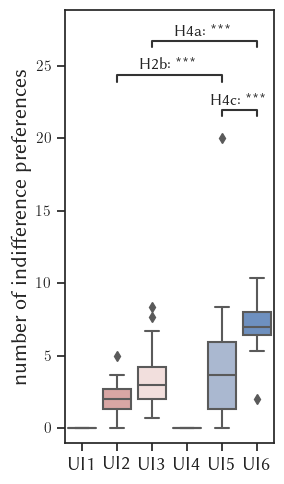

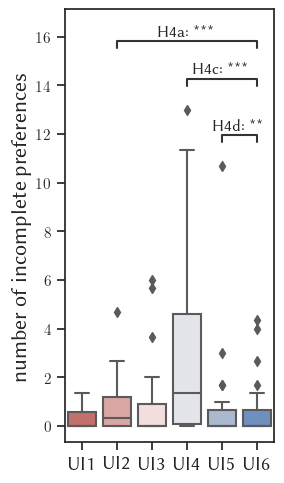

In [14]:
fig, axes = plt.subplots(1, 1, figsize=(3, 5))
sns.boxplot(ax=axes, x='interface', y='ties', order=interfaces, data=df_incomplete_text, palette=colors, saturation=1)
axes.set_ylabel('number of indifference preferences', fontsize=16)
axes.set_xlabel('')
axes.set_xticklabels(['UI1', 'UI2', 'UI3', 'UI4', 'UI5', 'UI6'], fontsize=14)
annot = Annotator(axes, [
    # ('pointwise', 'pairwise'),               # H1
    # ('pointwise', 'listwise-rating'),        # H2a
    ('pairwise',  'listwise-cantie'),        # H2b
    # ('listwise-rating', 'listwise-cantie'),  # H3a
    # ('listwise-notie', 'listwise-cantie'),   # H3b
    ('listwise-ranking', 'listwise-rating'), # H4a
    # ('listwise-ranking', 'listwise-notie'),  # H4b
    ('listwise-ranking', 'listwise-cantie'), # H4c
], data=df_incomplete, x='interface', y='ties', order=interfaces, show_non_significant=True)
# annot.configure(test='Mann-Whitney', text_format='star', loc='inside')
# annot.apply_and_annotate()
annot.set_custom_annotations(['H2b: ***', 'H4a: ***', 'H4c: ***'])
annot.annotate()
plt.tight_layout()
plt.savefig('figures/indifference_text.pdf', bbox_inches='tight')

fig, axes = plt.subplots(1, 1, figsize=(3, 5))
sns.boxplot(ax=axes, x='interface', y='incomplete', order=interfaces, data=df_incomplete_text, palette=colors, saturation=1)
axes.set_ylabel('number of incomplete preferences', fontsize=16)
axes.set_xlabel('')
axes.set_xticklabels(['UI1', 'UI2', 'UI3', 'UI4', 'UI5', 'UI6'], fontsize=14)
annot = Annotator(axes, [
    # ('pointwise', 'pairwise'),               # H1
    # ('pointwise', 'listwise-rating'),        # H2a
    # ('pairwise',  'listwise-cantie'),        # H2b
    # ('listwise-rating', 'listwise-cantie'),  # H3a
    # ('listwise-notie', 'listwise-cantie'),   # H3b
    ('listwise-ranking', 'pairwise'),        # H4a
    # ('listwise-ranking', 'listwise-rating'), # H4b
    ('listwise-ranking', 'listwise-notie'),  # H4c
    ('listwise-ranking', 'listwise-cantie'), # H4d
], data=df_incomplete, x='interface', y='incomplete', order=interfaces, show_non_significant=True)
# annot.configure(test='Mann-Whitney', text_format='star', loc='inside')
# annot.apply_and_annotate()
annot.set_custom_annotations(['H4a: ***', 'H4c: ***', 'H4d: **'])
annot.annotate()

# sns.boxplot(ax=axes[2], x='interface', y='total', order=interfaces, data=df_incomplete, palette=colors)
# axes[2].set_ylabel('Number of Incomplete Preferences')
# axes[2].set_xlabel('')
# axes[2].set_xticklabels(['UI1', 'UI2', 'UI3', 'UI4', 'UI5', 'UI6'], fontsize=12)

plt.tight_layout()
plt.savefig('figures/incomplete_text.pdf', bbox_inches='tight')

p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

listwise-cantie vs. listwise-ranking: H4c: ***
pairwise vs. listwise-cantie: H2b: ***
listwise-rating vs. listwise-ranking: H4a: ***
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

listwise-cantie vs. listwise-ranking: H4d: **
listwise-notie vs. listwise-ranking: H4c: ***
pairwise vs. listwise-ranking: H4a: ***


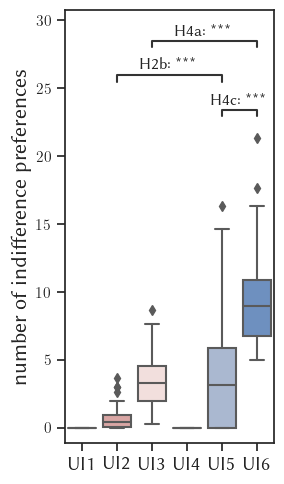

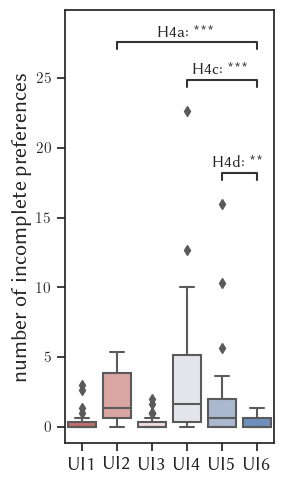

In [19]:
fig, axes = plt.subplots(1, 1, figsize=(3, 5))
sns.boxplot(ax=axes, x='interface', y='ties', order=interfaces, data=df_incomplete_image, palette=colors, saturation=1)
axes.set_ylabel('number of indifference preferences', fontsize=16)
axes.set_xlabel('')
axes.set_xticklabels(['UI1', 'UI2', 'UI3', 'UI4', 'UI5', 'UI6'], fontsize=14)
annot = Annotator(axes, [
    # ('pointwise', 'pairwise'),               # H1
    # ('pointwise', 'listwise-rating'),        # H2a
    ('pairwise',  'listwise-cantie'),        # H2b
    # ('listwise-rating', 'listwise-cantie'),  # H3a
    # ('listwise-notie', 'listwise-cantie'),   # H3b
    ('listwise-ranking', 'listwise-rating'), # H4a
    # ('listwise-ranking', 'listwise-notie'),  # H4b
    ('listwise-ranking', 'listwise-cantie'), # H4c
], data=df_incomplete, x='interface', y='ties', order=interfaces, show_non_significant=True)
# annot.configure(test='Mann-Whitney', text_format='star', loc='inside')
# annot.apply_and_annotate()
annot.set_custom_annotations(['H2b: ***', 'H4a: ***', 'H4c: ***'])
annot.annotate()
plt.tight_layout()
plt.savefig('figures/indifference_image.pdf', bbox_inches='tight')

fig, axes = plt.subplots(1, 1, figsize=(3, 5))
sns.boxplot(ax=axes, x='interface', y='incomplete', order=interfaces, data=df_incomplete_image, palette=colors, saturation=1)
axes.set_ylabel('number of incomplete preferences', fontsize=16)
axes.set_xlabel('')
axes.set_xticklabels(['UI1', 'UI2', 'UI3', 'UI4', 'UI5', 'UI6'], fontsize=14)
annot = Annotator(axes, [
    # ('pointwise', 'pairwise'),               # H1
    # ('pointwise', 'listwise-rating'),        # H2a
    # ('pairwise',  'listwise-cantie'),        # H2b
    # ('listwise-rating', 'listwise-cantie'),  # H3a
    # ('listwise-notie', 'listwise-cantie'),   # H3b
    ('listwise-ranking', 'pairwise'),        # H4a
    # ('listwise-ranking', 'listwise-rating'), # H4b
    ('listwise-ranking', 'listwise-notie'),  # H4c
    ('listwise-ranking', 'listwise-cantie'), # H4d
], data=df_incomplete, x='interface', y='incomplete', order=interfaces, show_non_significant=True)
# annot.configure(test='Mann-Whitney', text_format='star', loc='inside')
# annot.apply_and_annotate()
annot.set_custom_annotations(['H4a: ***', 'H4c: ***', 'H4d: **'])
annot.annotate()

# sns.boxplot(ax=axes[2], x='interface', y='total', order=interfaces, data=df_incomplete, palette=colors)
# axes[2].set_ylabel('Number of Incomplete Preferences')
# axes[2].set_xlabel('')
# axes[2].set_xticklabels(['UI1', 'UI2', 'UI3', 'UI4', 'UI5', 'UI6'], fontsize=12)

plt.tight_layout()
plt.savefig('figures/incomplete_image.pdf', bbox_inches='tight')